# Notebook 05 — Narrative Position, Star Power and Success (v2)

**Question:** after accounting for year, genre, runtime, language and the people involved, is a film's *position in plot space* associated with how it performs — commercially (revenue), critically (rating) and in attention (popularity)? And do some narrative communities do better than others?

This is **association analysis**, not causal proof. Thesis-safe wording: *"plot-network features are associated with success"*, not *"cause success"*.

### What changed from v1
| # | Change | Why it matters |
|---|--------|----------------|
| 1 | **Collinearity removed.** v1 put weighted degree and PageRank (Spearman ρ = 0.94) in the same model; their coefficients came out large and opposite (−0.74 / +0.78 on log revenue) — a textbook collinearity artefact, not a finding. v2 uses a small, non-redundant set and reports variance-inflation factors. v1's specification is re-estimated in the robustness section to show the problem. | Coefficients you can interpret. |
| 2 | **Plot novelty** (how far a film's overview is from its 20 most similar films, from the embeddings) with a squared term, testing the *optimal distinctiveness* idea: success may peak for stories that are neither too familiar nor too unusual (Askin & Mauskapf, 2017). | A direct test of the thesis's plot-based idea. |
| 3 | **Star power without look-ahead.** v1 counted an actor's appearances in the *same* 19k films, including films made *after* the one being predicted. v2 counts only **earlier** films in the full 98k thesis corpus: prior films and prior audience reach (votes) of the cast and the director. | No information from the future leaks into the predictors. |
| 4 | **Market revenue percentile.** Revenue is ranked within year against all thesis films with revenue (13k), not only network films (Notebook 02 showed the two definitions differ). | Percentiles mean "position in that year's market". |
| 5 | **Stronger controls:** year fixed effects (not a straight line), genre, runtime, English-language original. Robustness adds log budget. | Revenue is strongly tied to language and budget. |
| 6 | **Nested models on one sample** (controls → + plot network → + star power → + community) with the gain in R² for each block, and **standard errors clustered by community**. | Shows how much plot position adds beyond the usual explanations. |
| 7 | **Community effects with confidence intervals** for the 35 labelled communities (small ones pooled as "minor"). | Answers "which narratives succeed?" with uncertainty. |
| 8 | **Robustness:** budget control, network-reference percentile, logistic model for top-25% revenue, ≥ 100 votes, excluding minor and franchise communities, v1 specification. | Results that hold up. |

Output files keep their v1 names; new tables and figures go to `outputs/tables/success/` and `outputs/figures/success/`.

In [1]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 1 — CONFIG
# ═══════════════════════════════════════════════════════════════════════════
CFG = {
    "project_dir": "/content/drive/MyDrive/thesis_movie_project",

    # ── outcomes ─────────────────────────────────────────────────────────────
    "high_revenue_cut": 0.75,            # top 25% of the year's market = "high revenue"
    "revenue_reference": "market",       # "market" (all thesis films with revenue) or "network" (v1)

    # ── plot-network predictors ─────────────────────────────────────────────
    "novelty_k": 20,                      # novelty = 1 − mean cosine to the k most similar overviews
    "novelty_squared": True,              # test an inverted U (optimal distinctiveness)
    "network_terms": ["z_novelty", "z_log_betweenness", "z_participation", "z_clustering"],

    # ── star power (only films released in EARLIER years count) ────────────
    "cast_top_n": 5,                      # cast members listed per film in cast_clean
    "star_top_share": 0.10,               # "has_star" = cast star index in the top 10% of its release year

    # ── models ───────────────────────────────────────────────────────────────
    "min_genre_films": 100,               # rarer primary genres are pooled as "Other"
    "cluster_se_by": "community_group",   # standard errors clustered by community (35 major + "minor")
    "robust_min_votes": 100,

    "figure_dpi": 200,
}
print("CONFIG loaded.")


CONFIG loaded.


In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 2 — Imports, Drive mount, paths, figure style, helpers
# ═══════════════════════════════════════════════════════════════════════════
import json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
try:
    display
except NameError:
    display = print

import os, shutil, time
def mount_drive():
    """Mount Google Drive in Colab. Safe to re-run."""
    try:
        from google.colab import drive
    except ImportError:
        print("Not running in Colab — using local paths.")
        return
    if os.path.ismount("/content/drive"):
        print("Google Drive already mounted.")
        return
    if os.path.isdir("/content/drive") and os.listdir("/content/drive"):
        aside = f"/content/drive_local_leftover_{time.strftime('%Y%m%d_%H%M%S')}"
        shutil.move("/content/drive", aside)
        print(f"Moved a local leftover folder (not your Drive) to {aside}.")
    drive.mount("/content/drive")
mount_drive()

PROJECT_DIR = Path(CFG["project_dir"])
if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}. Check that Google Drive is mounted "
                            "(left sidebar → Files → drive/MyDrive) and that CFG['project_dir'] is right.")
CORE_DIR     = PROJECT_DIR / "processed" / "core"
NETWORK_DIR  = PROJECT_DIR / "processed" / "network"
FEATURES_DIR = PROJECT_DIR / "processed" / "features"
TABLES_DIR   = PROJECT_DIR / "outputs" / "tables"
FIG_DIR      = PROJECT_DIR / "outputs" / "figures"
S_TABLES     = TABLES_DIR / "success"
S_FIGS       = FIG_DIR / "success"
for d in [FEATURES_DIR, TABLES_DIR, FIG_DIR, S_TABLES, S_FIGS]:
    d.mkdir(parents=True, exist_ok=True)

NODES_FILE     = NETWORK_DIR / "semantic_network_nodes_lcc.csv"
POSITIONS_FILE = NETWORK_DIR / "node_positions_nb04.csv"
MANIFEST_FILE  = NETWORK_DIR / "network_manifest.json"
LABELED_FILE   = TABLES_DIR / "community_manual_labeling_template_labeled.csv"
THESIS_FILE    = CORE_DIR / "df_thesis_films.csv"
NETWORK_CORPUS = CORE_DIR / "df_network_corpus.csv"
FRANCHISE_FILE = TABLES_DIR / "interpretation" / "franchise_or_name_driven_communities.csv"
MODELING_TABLE_OUT = FEATURES_DIR / "modeling_table_success_star_power.csv"

# ── figure style shared with Notebooks 02–04 ─────────────────────────────────
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 24,
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "font.family": "DejaVu Sans", "lines.linewidth": 2, "legend.frameon": False,
})

def subtitle(ax, text):
    ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6), textcoords="offset points",
                fontsize=9.5, color=INK_2, va="bottom", ha="left")

def save(fig, table, name):
    fig.savefig(S_FIGS / f"{name}.png", dpi=CFG["figure_dpi"], bbox_inches="tight")
    table.to_csv(S_TABLES / f"{name}.csv", index=False)
    plt.show()
    print(f"  ✓ figures/success/{name}.png + tables/success/{name}.csv")

def save_v1(df, name):
    df.to_csv(TABLES_DIR / name, index=False)
    print(f"  ✓ tables/{name}")

def save_new(df, name):
    df.to_csv(S_TABLES / name, index=False)
    print(f"  ✓ tables/success/{name}")

def z(s):
    s = pd.to_numeric(s, errors="coerce")
    return (s - s.mean()) / s.std()

print("PROJECT_DIR:", PROJECT_DIR)


Google Drive already mounted.
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project


## 1. Load the network, the labels and the thesis corpus

The labelled file must belong to the **current** communities; otherwise old labels would be attached to new community numbers, so the notebook stops.

In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 3 — Load inputs and check they belong together
# ═══════════════════════════════════════════════════════════════════════════
required = {"nodes": NODES_FILE, "labels": LABELED_FILE, "thesis": THESIS_FILE}
missing = [k for k, p in required.items() if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run Notebooks 01, 03 and 04 v2 first.")

nodes = pd.read_csv(NODES_FILE)
labels = pd.read_csv(LABELED_FILE)
thesis = pd.read_csv(THESIS_FILE, low_memory=False)
positions = pd.read_csv(POSITIONS_FILE) if POSITIONS_FILE.exists() else None
manifest = json.loads(MANIFEST_FILE.read_text()) if MANIFEST_FILE.exists() else {}
print(f"network films {len(nodes):,} · labelled communities {len(labels)} · thesis corpus {len(thesis):,}")

sizes = nodes["community_id"].value_counts()
stale = [(c, n) for c, n in zip(labels["community_id"], labels["n_films"]) if sizes.get(c) != n]
if stale:
    raise ValueError(f"The labelled file does not match the current communities (e.g. {stale[:3]}). "
                     "Re-run Notebook 04 v2 until it writes the labelled file, then run this notebook.")
print("Labels match the current network ✓")

MAJOR = labels["community_id"].tolist()
lab = labels.set_index("community_id")
short_col = "short_label" if "short_label" in lab and lab["short_label"].notna().any() else "suggested_label_manual"
SHORT = {c: f"C{c} · {lab.loc[c, short_col]}" for c in MAJOR}

df = nodes.merge(labels[["community_id", "suggested_label_manual", "interpretation_note_manual"]],
                 on="community_id", how="left")
df["suggested_label_manual"] = df["suggested_label_manual"].fillna("Minor community (pooled)")
df["interpretation_note_manual"] = df["interpretation_note_manual"].fillna("Minor community not labelled individually.")
df["community_group"] = np.where(df["community_id"].isin(MAJOR), "C" + df["community_id"].astype(str), "minor")

if positions is not None:
    keep = [c for c in ["participation_coefficient", "within_community_strength", "external_share"] if c in positions]
    df = df.merge(positions[["tmdb_id"] + keep], on="tmdb_id", how="left")
    print("Film positions from Notebook 04 attached:", keep)
else:
    print("node_positions_nb04.csv not found — participation coefficient unavailable (run Notebook 04 v2).")
    df["participation_coefficient"] = np.nan

extra = thesis[["tmdb_id", "original_language", "budget_clean"]].drop_duplicates("tmdb_id")
df = df.drop(columns=[c for c in ["original_language", "budget_clean"] if c in df]).merge(extra, on="tmdb_id", how="left")
print(f"modelling base: {df.shape}")


network films 19,084 · labelled communities 35 · thesis corpus 98,037
Labels match the current network ✓
Film positions from Notebook 04 attached: ['participation_coefficient', 'within_community_strength', 'external_share']
modelling base: (19084, 41)


## 2. Outcomes

* **log revenue** and **revenue percentile within release year** — the percentile ranks each film against *all thesis films with revenue released that year* (the market), so 0.80 means "earned more than 80% of that year's films with known revenue". `high_revenue` = top 25%.
* **vote average** — audience rating (TMDB).
* **log popularity** — current attention on TMDB.

Revenue is known for about 40% of films; revenue models use that subset only, and the sample audit shows how it differs from the rest.

In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 4 — Outcomes (market-reference revenue percentile)
# ═══════════════════════════════════════════════════════════════════════════
for c in ["release_year", "runtime", "popularity", "vote_average", "vote_count", "revenue_clean", "budget_clean"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["log_revenue"] = np.log1p(df["revenue_clean"].where(df["revenue_clean"] > 0))
df["log_popularity"] = np.log1p(df["popularity"].where(df["popularity"] > 0))
df["log_budget"] = np.log1p(df["budget_clean"].where(df["budget_clean"] > 0))

market = thesis[pd.to_numeric(thesis["revenue_clean"], errors="coerce") > 0][["tmdb_id", "release_year", "revenue_clean"]].copy()
market["pct_market"] = market.groupby("release_year")["revenue_clean"].rank(pct=True)
df = df.merge(market[["tmdb_id", "pct_market"]], on="tmdb_id", how="left")
has_rev = df["revenue_clean"] > 0
df["pct_network"] = np.where(has_rev, df["revenue_clean"].where(has_rev).groupby(df["release_year"]).rank(pct=True), np.nan)
df["revenue_percentile_year"] = df["pct_market"] if CFG["revenue_reference"] == "market" else df["pct_network"]
df["high_revenue_year"] = np.where(df["revenue_percentile_year"].notna(),
                                   (df["revenue_percentile_year"] >= CFG["high_revenue_cut"]).astype(float), np.nan)
both = df[["pct_market", "pct_network"]].dropna()
print(f"Revenue known: {has_rev.sum():,} films ({has_rev.mean():.1%}). "
      f"Market vs network percentile: Spearman ρ = {both.corr(method='spearman').iloc[0, 1]:.3f}, "
      f"mean shift {(both['pct_market'] - both['pct_network']).mean():+.3f} "
      "(network films sit higher in the market than among themselves).")


Revenue known: 7,547 films (39.5%). Market vs network percentile: Spearman ρ = 0.997, mean shift +0.063 (network films sit higher in the market than among themselves).


## 3. Star power without look-ahead

For every film in the **full thesis corpus**, each listed cast member and the director get two numbers computed **only from films released in earlier years**:
* **prior films** — how many earlier films they appear in (experience);
* **prior reach** — total TMDB votes of those earlier films (how widely their earlier work was seen).

A film's **star index** is the log of the highest prior reach among its listed cast; `has_star` marks films whose star index is in the top 10% of their release year. The cast field lists five people in credit order, which is not always billing order, so the *maximum* over the listed cast is used rather than "the first-billed star".

In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 5 — Leakage-free star power for cast and director (vectorised)
# ═══════════════════════════════════════════════════════════════════════════
def prior_career(people_films):
    """people_films: columns person, tmdb_id, release_year, votes → prior films / prior votes per (person, film),
    counting only films released in strictly earlier years."""
    py = (people_films.groupby(["person", "release_year"])
          .agg(n=("tmdb_id", "size"), v=("votes", "sum")).reset_index()
          .sort_values(["person", "release_year"]))
    g = py.groupby("person")
    py["prior_films"] = g["n"].cumsum() - py["n"]          # everything before this year
    py["prior_votes"] = g["v"].cumsum() - py["v"]
    return people_films.merge(py[["person", "release_year", "prior_films", "prior_votes"]],
                              on=["person", "release_year"], how="left")

base = thesis[["tmdb_id", "release_year", "vote_count", "cast_clean", "director_name"]].copy()
base["votes"] = pd.to_numeric(base["vote_count"], errors="coerce").fillna(0)
cast = (base.assign(person=base["cast_clean"].fillna("").str.split(r"\s*,\s*", regex=True))
            .explode("person"))
cast["person"] = cast["person"].str.strip()
cast = cast[cast["person"].ne("") & cast["person"].notna()]
cast = cast.groupby("tmdb_id").head(CFG["cast_top_n"])
cast = prior_career(cast[["person", "tmdb_id", "release_year", "votes"]])
star = cast.groupby("tmdb_id").agg(cast_size=("person", "size"),
                                   star_prior_films_max=("prior_films", "max"),
                                   star_prior_votes_max=("prior_votes", "max")).reset_index()

dirs = base.assign(person=base["director_name"].fillna("").str.split(r"\s*,\s*", regex=True).str[0].str.strip())
dirs = dirs[dirs["person"].ne("")]
dirs = prior_career(dirs[["person", "tmdb_id", "release_year", "votes"]])
star = star.merge(dirs.groupby("tmdb_id").agg(director_prior_films=("prior_films", "max"),
                                              director_prior_votes=("prior_votes", "max")).reset_index(),
                  on="tmdb_id", how="outer")

df = df.drop(columns=[c for c in star.columns if c in df.columns and c != "tmdb_id"]).merge(star, on="tmdb_id", how="left")
for c in ["cast_size", "star_prior_films_max", "star_prior_votes_max", "director_prior_films", "director_prior_votes"]:
    df[c] = df[c].fillna(0)
df["star_index"] = np.log1p(df["star_prior_votes_max"])
df["director_index"] = np.log1p(df["director_prior_votes"])
df["has_star"] = (df["star_index"] >= df.groupby("release_year")["star_index"]
                  .transform(lambda x: x.quantile(1 - CFG["star_top_share"]))).astype(int)
df["is_english"] = df["original_language"].fillna("").eq("en").astype(int)

# v1 columns kept for the bricks (computed the v1 way, on the corrected cast field)
cl = df["cast_clean"].fillna("").str.split(r"\s*,\s*", regex=True).map(lambda x: [a for a in x if a][:CFG["cast_top_n"]])
counts = cl.explode().value_counts()
exp_ = cl.explode().map(counts).groupby(level=0)
df["top_cast_exposure_sum"] = exp_.sum().reindex(df.index).fillna(0)
df["top_cast_exposure_max"] = exp_.max().reindex(df.index).fillna(0)
df["top_cast_exposure_mean"] = exp_.mean().reindex(df.index).fillna(0)
df["has_high_exposure_actor"] = (df["top_cast_exposure_max"] >= counts.quantile(0.90)).astype(int)
df["has_cast"] = (df["cast_size"] > 0).astype(int)

print(f"Cast records in thesis corpus: {len(cast):,} · people: {cast['person'].nunique():,}")
display(df[["star_index", "director_index", "star_prior_films_max", "has_star"]].describe().round(2))
top = (df.sort_values("star_index", ascending=False)[["title", "release_year", "star_index", "cast_clean"]].head(8))
print("Highest star index in the network (sanity check):"); display(top)


Cast records in thesis corpus: 463,929 · people: 256,495


,star_index,director_index,star_prior_films_max,has_star
count,19084.00,19084.00,19084.00,19084.00
mean,5.23,3.48,5.02,0.11
std,2.95,3.25,6.09,0.31
min,0.00,0.00,0.00,0.00
25%,3.30,0.00,1.00,0.00
50%,5.68,3.53,3.00,0.00
75%,7.53,6.08,7.00,0.00
max,11.84,12.29,88.00,1.00


Highest star index in the network (sanity check):


,title,release_year,star_index,cast_clean
15643,Darkest Hour,2017,11.843200,"Jeremy Child, Malcolm Storry, Gary Oldman, Sarah Flind, Steffan Donnelly"
8008,Harry Potter and the Deathly Hallows: Part 2,2011,11.671944,"Jim Broadbent, Ruby Evans, Natalia Tena, Kelly Macdonald, Gary Oldman"
7074,A Christmas Carol,2009,11.568512,"Sonje Fortag, Ron Bottitta, Amber Gainey Meade, Michael Hyland, Gary Oldman"
8656,Hitpig!,2024,11.517893,"Larissa Gallagher, Lilly Singh, Rainn Wilson, May Charters, Andy Serkis"
15564,SAS: Red Notice,2021,11.512115,"Hannah John-Kamen, Andy Serkis, Noel Clarke, Jing Lusi, Sarah Winter"
9338,Arthur Christmas,2011,11.365133,"Robbie Coltrane, Julia Davis, Michael Palin, Deborah Findlay, Clint Dyer"
17471,Retribution,2023,11.364019,"Liam Neeson, Matthew Modine, Daniel Grave, Christian Koerner, Arian Moayed"
9183,Blacklight,2022,11.349382,"Dailin Gabrielle, Andrew Shaw, Rodney Miller, Liam Neeson, Yael Stone"


## 4. Plot-network predictors

| Predictor | Meaning |
|---|---|
| **novelty** | 1 − mean cosine similarity to the film's 20 most similar overviews (masked text, as in Notebook 03). High = an unusual plot. |
| **log betweenness** (exact) | how often the film lies on shortest paths between other films — a bridge between narratives. |
| **participation** | how evenly the film's similar films are spread across communities — a hybrid plot. |
| **clustering** | whether the film's neighbours are also similar to each other — a tightly knit, formulaic niche. |

Weighted degree and PageRank are left out of the main models: they largely measure the same thing as novelty (in reverse) and as each other. The variance-inflation table below shows the chosen set is not redundant.

In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 6 — Novelty from the embeddings, network features, collinearity check
# ═══════════════════════════════════════════════════════════════════════════
masked = bool(manifest.get("config", {}).get("mask_person_names", False))
tag = "_names_masked" if masked else ""
emb_file, idx_file = FEATURES_DIR / f"sbert_minilm_embeddings{tag}.npy", FEATURES_DIR / f"sbert_minilm_embedding_index{tag}.csv"
if not idx_file.exists():
    idx_file = FEATURES_DIR / "sbert_minilm_embedding_index.csv"
if emb_file.exists() and idx_file.exists():
    from sklearn.neighbors import NearestNeighbors
    E = np.load(emb_file).astype(np.float32)
    ids = pd.read_csv(idx_file, usecols=["tmdb_id"])["tmdb_id"].values
    nn = NearestNeighbors(n_neighbors=CFG["novelty_k"] + 1, metric="cosine", algorithm="brute").fit(E)
    dist, _ = nn.kneighbors(E)
    novelty = pd.Series(dist[:, 1:].mean(axis=1), index=ids)          # mean cosine distance, self excluded
    df["novelty"] = df["tmdb_id"].map(novelty[~novelty.index.duplicated()])
    print(f"Novelty from {emb_file.name} ({'person names masked' if masked else 'unmasked text'}): "
          f"mean {df['novelty'].mean():.3f}, sd {df['novelty'].std():.3f}")
else:
    print("Embeddings not found — novelty approximated from weighted degree (fewer/weaker neighbours = more novel).")
    df["novelty"] = -np.log1p(df["weighted_degree"])

BETW = "betweenness_centrality" if "betweenness_centrality" in df else "betweenness_centrality_sampled"
df["log_betweenness"] = np.log1p(df[BETW] * len(df))       # rescaled so the log is not squashed near zero
df["participation"] = df["participation_coefficient"]
df["clustering"] = df["clustering_coefficient"]
for c in ["novelty", "log_betweenness", "participation", "clustering", "star_index", "director_index", "runtime",
          "weighted_degree", "pagerank", BETW, "clustering_coefficient", "cast_size", "top_cast_exposure_sum",
          "top_cast_exposure_max", "top_cast_exposure_mean", "degree", "eigenvector_centrality"]:
    if c in df:
        df[f"z_{c}"] = z(df[c])
df["z_novelty_sq"] = df["z_novelty"] ** 2
df["z_betweenness_centrality_sampled"] = z(df[BETW])       # v1 column name kept for the bricks

net_terms = [t for t in CFG["network_terms"] if df[t].notna().any()]
vif_cols = net_terms + ["z_star_index", "z_director_index", "z_runtime", "z_weighted_degree", "z_pagerank"]
def vifs(cols):
    X = df[cols].dropna().values
    X = np.column_stack([np.ones(len(X)), X])                     # intercept, so VIFs are the usual centred ones
    return dict(zip(cols, [variance_inflation_factor(X, i + 1) for i in range(len(cols))]))
main_cols = net_terms + ["z_star_index", "z_director_index", "z_runtime"]
vif = pd.DataFrame({"variable": vif_cols})
vif["VIF_with_weighted_degree_and_pagerank"] = vif["variable"].map(vifs(vif_cols))
vif["VIF_main_specification"] = vif["variable"].map(vifs(main_cols))
display(vif.round(2))
save_new(vif.round(3), "collinearity_vif.csv")
print("Rule of thumb: VIF > 5 means the variable is largely explained by the others.")


Novelty from sbert_minilm_embeddings_names_masked.npy (person names masked): mean 0.471, sd 0.056


,variable,VIF_with_weighted_degree_and_pagerank,VIF_main_specification
0,z_novelty,3.02,1.33
1,z_log_betweenness,7.06,1.52
2,z_participation,1.66,1.32
3,z_clustering,1.25,1.13
4,z_star_index,1.05,1.05
5,z_director_index,1.11,1.11
6,z_runtime,1.07,1.07
7,z_weighted_degree,13.14,NaN
8,z_pagerank,14.71,NaN


  ✓ tables/success/collinearity_vif.csv
Rule of thumb: VIF > 5 means the variable is largely explained by the others.


## 5. Sample audit — who has revenue data?

Revenue is not missing at random: films with revenue are more visible, more often English-language and more often major releases. Reading the revenue models, keep in mind they describe the *reported-revenue* market.

In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 7 — Sample audit (v1 file) + comparison of films with and without revenue
# ═══════════════════════════════════════════════════════════════════════════
audit = pd.DataFrame([
    {"metric": "network_lcc_rows", "value": len(df)},
    {"metric": "revenue_available_rows", "value": int(has_rev.sum())},
    {"metric": "revenue_available_pct", "value": round(has_rev.mean() * 100, 2)},
    {"metric": "revenue_percentile_available_rows", "value": int(df["revenue_percentile_year"].notna().sum())},
    {"metric": "vote_average_available_rows", "value": int(df["vote_average"].notna().sum())},
    {"metric": "popularity_available_rows", "value": int(df["popularity"].notna().sum())},
    {"metric": "has_cast_pct", "value": round(df["has_cast"].mean() * 100, 2)},
    {"metric": "median_cast_size", "value": float(df["cast_size"].median())},
    {"metric": "n_communities_total", "value": int(df["community_id"].nunique())},
    {"metric": "n_manual_labeled_communities", "value": len(MAJOR)},
    {"metric": "films_in_minor_communities", "value": int(df["community_group"].eq("minor").sum())},
    {"metric": "revenue_reference", "value": CFG["revenue_reference"]},
    {"metric": "novelty_source", "value": emb_file.name if emb_file.exists() else "weighted_degree proxy"},
])
display(audit)
save_v1(audit, "modeling_sample_audit.csv")

grp = np.where(has_rev, "revenue known", "revenue missing")
selection = df.groupby(grp)[["vote_count", "vote_average", "popularity", "runtime", "star_index", "novelty",
                             "release_year"]].median().T
selection.loc["share English-language"] = df.groupby(grp)["is_english"].mean()
selection.columns.name = None
display(selection.round(3))
save_new(selection.round(4).reset_index().rename(columns={"index": "variable (median unless share)"}),
         "revenue_selection_profile.csv")


,metric,value
0,network_lcc_rows,19084
1,revenue_available_rows,7547
2,revenue_available_pct,39.55
3,revenue_percentile_available_rows,7547
4,vote_average_available_rows,19084
5,popularity_available_rows,19084
6,has_cast_pct,99.92
7,median_cast_size,5.0
8,n_communities_total,105
9,n_manual_labeled_communities,35


  ✓ tables/modeling_sample_audit.csv


,revenue known,revenue missing
vote_count,363.000,58.000
vote_average,6.400,6.000
popularity,2.536,1.250
runtime,103.000,96.000
star_index,6.142,5.416
novelty,0.473,0.470
release_year,2010.000,2014.000
share English-language,0.649,0.455


  ✓ tables/success/revenue_selection_profile.csv


  ✓ tables/network_success_correlations.csv


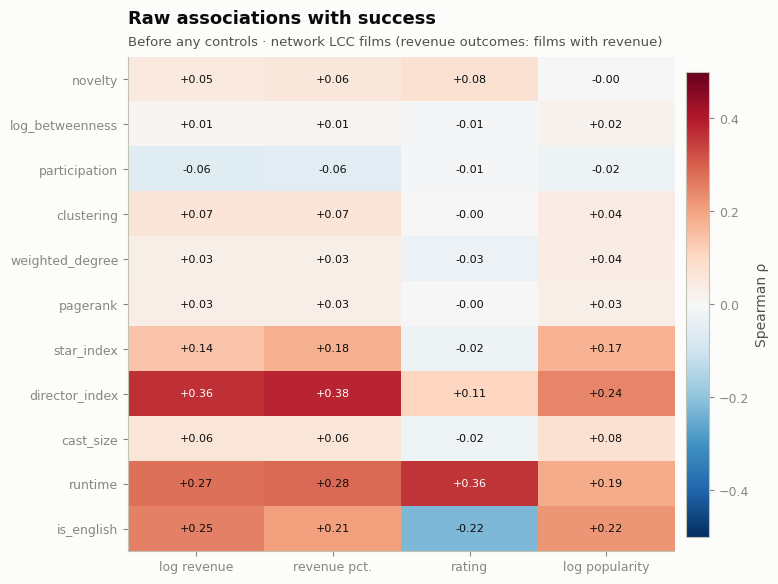

  ✓ figures/success/fig_01_correlations.png + tables/success/fig_01_correlations.csv


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 8 — Correlations: outcomes × predictors (v1 file + clearer figure)
# ═══════════════════════════════════════════════════════════════════════════
outcomes = ["log_revenue", "revenue_percentile_year", "vote_average", "log_popularity"]
predictors = ["novelty", "log_betweenness", "participation", "clustering", "weighted_degree", "pagerank",
              "star_index", "director_index", "cast_size", "runtime", "is_english"]
predictors = [p for p in predictors if p in df and df[p].notna().any()]
corr_full = df[outcomes + predictors].corr(method="spearman", min_periods=100)
corr_full.to_csv(TABLES_DIR / "network_success_correlations.csv")
print("  ✓ tables/network_success_correlations.csv")

CT = corr_full.loc[predictors, outcomes]
fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(predictors) + 1.8))
im = ax.imshow(CT.values, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
ax.set_xticks(range(len(outcomes)), ["log revenue", "revenue pct.", "rating", "log popularity"])
ax.set_yticks(range(len(predictors)), predictors)
ax.grid(False)
for i in range(CT.shape[0]):
    for j in range(CT.shape[1]):
        ax.text(j, i, f"{CT.values[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(CT.values[i, j]) > 0.3 else INK)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="Spearman ρ")
ax.set_title("Raw associations with success")
subtitle(ax, "Before any controls · network LCC films (revenue outcomes: films with revenue)")
save(fig, CT.reset_index().rename(columns={"index": "predictor"}), "fig_01_correlations")


## 6. Nested regression models

Same films in all four models of one outcome, so the R² gains are comparable:

| Model | Adds |
|---|---|
| **M1** controls | release-year fixed effects, primary genre, runtime, English-language original |
| **M2** + plot network | novelty (+ novelty²), log betweenness, participation, clustering |
| **M3** + star power | cast star index, director index, has_star |
| **M4** + community | the 35 labelled communities (minor ones pooled) |

OLS with standard errors clustered by community. Coefficients of standardised predictors are "change in the outcome per one standard deviation".

In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 9 — Fit M1–M4 for every outcome
# ═══════════════════════════════════════════════════════════════════════════
gc = df["primary_genre"].fillna("Unknown").astype(str)
small = gc.map(gc.value_counts()) < CFG["min_genre_films"]
df["primary_genre_model"] = gc.where(~small, "Other")
df["community_id_model"] = df["community_id"].astype(str)          # v1 column
df["release_year_centered"] = df["release_year"] - df["release_year"].median()   # v1 column

NET = " + ".join(net_terms + (["z_novelty_sq"] if CFG["novelty_squared"] and "z_novelty" in net_terms else []))
STAR = "z_star_index + z_director_index + has_star"
CTRL = "C(release_year) + C(primary_genre_model) + z_runtime + is_english"
COMM = "C(community_group, Treatment('minor'))"
SPECS = {"M1_controls": CTRL, "M2_add_plot_network": f"{CTRL} + {NET}",
         "M3_add_star_power": f"{CTRL} + {NET} + {STAR}", "M4_add_community": f"{CTRL} + {NET} + {STAR} + {COMM}"}
OUTCOMES = {"log_revenue": "log revenue", "revenue_percentile_year": "revenue percentile in year",
            "vote_average": "rating (vote average)", "log_popularity": "log popularity"}
MODEL_VARS = ["release_year", "primary_genre_model", "z_runtime", "is_english", "z_star_index", "z_director_index",
              "has_star", "community_group", CFG["cluster_se_by"]] + net_terms + ["z_novelty_sq"]

def fit(formula, data, cluster=CFG["cluster_se_by"]):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(data[cluster])[0]})

def tidy(res, outcome, model):
    ci = res.conf_int()
    return pd.DataFrame({"outcome": outcome, "model": model, "term": res.params.index, "coef": res.params.values,
                         "ci_low": ci[0].values, "ci_high": ci[1].values, "p_value": res.pvalues.values,
                         "n_obs": int(res.nobs), "r_squared": res.rsquared, "adj_r_squared": res.rsquared_adj})

fits, tables, r2 = {}, {}, []
for y in OUTCOMES:
    data = df.dropna(subset=[y] + list(dict.fromkeys(MODEL_VARS))).copy()
    rows = []
    for m, rhs in SPECS.items():
        res = fit(f"{y} ~ {rhs}", data)
        fits[(y, m)] = res
        rows.append(tidy(res, y, m))
        r2.append({"outcome": y, "model": m, "n_obs": int(res.nobs), "r_squared": res.rsquared,
                   "adj_r_squared": res.rsquared_adj})
    tables[y] = pd.concat(rows, ignore_index=True)
    # joint test: does the plot-network block matter once everything else is in? (M4)
    names = [t for t in fits[(y, "M4_add_community")].params.index if t in NET.split(" + ")]
    w = fits[(y, "M4_add_community")].wald_test(" , ".join(f"{t} = 0" for t in names), scalar=True)
    r2.append({"outcome": y, "model": "joint test plot-network block (M4)", "n_obs": int(res.nobs),
               "r_squared": np.nan, "adj_r_squared": np.nan, "wald_F": float(w.statistic), "wald_p": float(w.pvalue)})
    print(f"{y:25s} n={int(res.nobs):6,}  R²: " + " → ".join(f"{fits[(y, m)].rsquared:.3f}" for m in SPECS)
          + f"  | plot-network block p={float(w.pvalue):.2g}")

r2 = pd.DataFrame(r2)
save_new(r2.round(5), "model_fit_summary.csv")
v1_names = {"log_revenue": "regression_results_log_revenue.csv", "revenue_percentile_year": "regression_results_revenue_percentile.csv",
            "vote_average": "regression_results_vote_average.csv", "log_popularity": "regression_results_popularity.csv"}
for y, t in tables.items():
    save_v1(t, v1_names[y])


log_revenue               n= 7,547  R²: 0.238 → 0.241 → 0.292 → 0.304  | plot-network block p=0.0016
revenue_percentile_year   n= 7,547  R²: 0.233 → 0.238 → 0.297 → 0.310  | plot-network block p=0.00023
vote_average              n=19,084  R²: 0.259 → 0.259 → 0.265 → 0.274  | plot-network block p=0.1
log_popularity            n=19,084  R²: 0.158 → 0.158 → 0.203 → 0.210  | plot-network block p=0.016
  ✓ tables/success/model_fit_summary.csv
  ✓ tables/regression_results_log_revenue.csv
  ✓ tables/regression_results_revenue_percentile.csv
  ✓ tables/regression_results_vote_average.csv
  ✓ tables/regression_results_popularity.csv


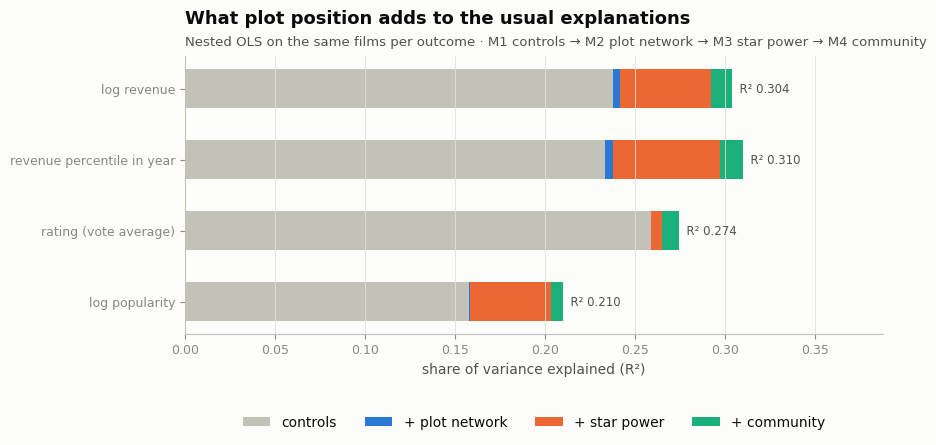

  ✓ figures/success/fig_02_r2_by_block.png + tables/success/fig_02_r2_by_block.csv
  ✓ tables/regression_key_coefficients_summary.csv


,outcome,term,coef_rounded,ci_low,ci_high,p_value_rounded
0,log_revenue,z_novelty,0.0997,-0.0138,0.2133,0.0851
1,log_revenue,z_log_betweenness,0.0930,0.0127,0.1734,0.0232
2,log_revenue,z_participation,-0.0646,-0.1279,-0.0012,0.0459
3,log_revenue,z_clustering,0.0677,0.0072,0.1281,0.0283
4,log_revenue,z_novelty_sq,-0.0303,-0.0701,0.0095,0.1357
5,log_revenue,z_star_index,0.0983,0.0215,0.1752,0.0121
6,log_revenue,z_director_index,0.5979,0.5339,0.6619,0.0000
7,log_revenue,has_star,0.2592,0.0736,0.4448,0.0062
8,revenue_percentile_year,z_novelty,0.0110,-0.0002,0.0223,0.0552
9,revenue_percentile_year,z_log_betweenness,0.0120,0.0048,0.0191,0.0011


In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 10 — Figure: what each block adds (R² gain) + key coefficient table (v1 file)
# ═══════════════════════════════════════════════════════════════════════════
fitrows = r2[r2["model"].isin(SPECS)].pivot(index="outcome", columns="model", values="r_squared")[list(SPECS)]
gain = pd.DataFrame({"controls": fitrows["M1_controls"],
                     "+ plot network": fitrows["M2_add_plot_network"] - fitrows["M1_controls"],
                     "+ star power": fitrows["M3_add_star_power"] - fitrows["M2_add_plot_network"],
                     "+ community": fitrows["M4_add_community"] - fitrows["M3_add_star_power"]}).loc[list(OUTCOMES)]
fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(len(gain))
colors = [AXIS, SERIES[0], SERIES[1], SERIES[2]]
for col, c in zip(gain.columns, colors):
    ax.barh(range(len(gain)), gain[col], left=left, color=c, height=0.55, label=col)
    left += gain[col].values
for i, tot in enumerate(left):
    ax.text(tot, i, f"  R² {tot:.3f}", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(range(len(gain)), [OUTCOMES[o] for o in gain.index])
ax.invert_yaxis()
ax.set_xlim(0, left.max() * 1.25)
ax.set_xlabel("share of variance explained (R²)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4)
ax.set_title("What plot position adds to the usual explanations")
subtitle(ax, "Nested OLS on the same films per outcome · M1 controls → M2 plot network → M3 star power → M4 community")
save(fig, gain.reset_index().rename(columns={"index": "outcome"}), "fig_02_r2_by_block")

terms_of_interest = list(dict.fromkeys(NET.split(" + ") + ["z_star_index", "z_director_index", "has_star"]))
all_res = pd.concat(tables.values(), ignore_index=True)
key = all_res[all_res["term"].isin(terms_of_interest)].copy()
key["significant_05"] = key["p_value"] < 0.05
key["coef_rounded"], key["p_value_rounded"] = key["coef"].round(4), key["p_value"].round(4)
save_v1(key, "regression_key_coefficients_summary.csv")
display(key[key["model"] == "M4_add_community"][["outcome", "term", "coef_rounded", "ci_low", "ci_high", "p_value_rounded"]]
        .round(4).reset_index(drop=True))


## 7. Optimal distinctiveness: is there a sweet spot of plot novelty?

The curves show the predicted outcome across the range of novelty (from M4, all other variables at their means), with a 95% confidence band. An inverted U — highest in the middle — would mean audiences and markets reward stories that are *somewhat* new but not too strange.

,outcome,b_novelty,p_novelty,b_novelty_sq,p_novelty_sq,shape,turning_point_sd
0,log_revenue,0.0997,0.0851,-0.0303,0.1357,flat,1.6459
1,revenue_percentile_year,0.0110,0.0552,-0.0029,0.1126,flat,1.9064
2,vote_average,0.0040,0.8191,0.0060,0.4553,flat,-0.3325
3,log_popularity,0.0033,0.5652,0.0004,0.8485,flat,NaN


  ✓ tables/success/novelty_shape.csv


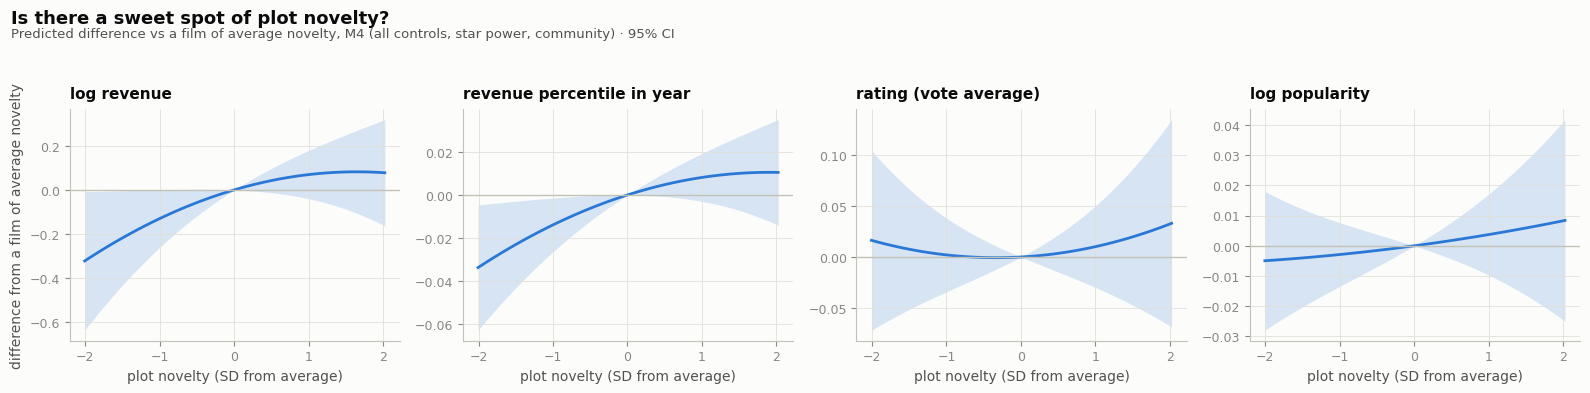

  ✓ figures/success/fig_03_novelty_sweet_spot.png + tables/success/fig_03_novelty_sweet_spot.csv


In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 11 — Predicted outcome across novelty (M4) with confidence bands
# ═══════════════════════════════════════════════════════════════════════════
grid = np.linspace(df["z_novelty"].quantile(0.02), df["z_novelty"].quantile(0.98), 60)
curves, turning = [], []
fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(4.0 * len(OUTCOMES), 3.6))
for ax, y in zip(np.atleast_1d(axes), OUTCOMES):
    res = fits[(y, "M4_add_community")]
    b, V_ = res.params, res.cov_params()
    b1, b2 = b.get("z_novelty", 0.0), b.get("z_novelty_sq", 0.0)
    pred = b1 * grid + b2 * grid ** 2                                # effect relative to average novelty
    var = (grid ** 2) * V_.loc["z_novelty", "z_novelty"]
    if "z_novelty_sq" in b:
        var = var + (grid ** 4) * V_.loc["z_novelty_sq", "z_novelty_sq"] + 2 * grid ** 3 * V_.loc["z_novelty", "z_novelty_sq"]
    se = np.sqrt(var)
    ax.fill_between(grid, pred - 1.96 * se, pred + 1.96 * se, color=SERIES[0], alpha=0.18, linewidth=0)
    ax.plot(grid, pred, color=SERIES[0])
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_title(OUTCOMES[y], fontsize=11, pad=8)
    ax.set_xlabel("plot novelty (SD from average)")
    curves.append(pd.DataFrame({"outcome": y, "z_novelty": grid, "effect": pred, "ci_low": pred - 1.96 * se,
                                "ci_high": pred + 1.96 * se}))
    tp = -b1 / (2 * b2) if b2 != 0 else np.nan
    turning.append({"outcome": y, "b_novelty": b1, "p_novelty": res.pvalues.get("z_novelty", np.nan),
                    "b_novelty_sq": b2, "p_novelty_sq": res.pvalues.get("z_novelty_sq", np.nan),
                    "shape": ("inverted U" if b2 < 0 else "U") if res.pvalues.get("z_novelty_sq", 1) < 0.05 else
                             ("rising" if b1 > 0 else "falling") if res.pvalues.get("z_novelty", 1) < 0.05 else "flat",
                    "turning_point_sd": tp if (np.isfinite(tp) and grid.min() <= tp <= grid.max()) else np.nan})
np.atleast_1d(axes)[0].set_ylabel("difference from a film of average novelty")
fig.suptitle("Is there a sweet spot of plot novelty?", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.08)
fig.text(0.01, 0.995, "Predicted difference vs a film of average novelty, M4 (all controls, star power, community) · 95% CI",
         fontsize=9.5, color=INK_2, va="bottom")
fig.tight_layout()
turning = pd.DataFrame(turning)
display(turning.round(4))
save_new(turning.round(5), "novelty_shape.csv")
save(fig, pd.concat(curves, ignore_index=True), "fig_03_novelty_sweet_spot")


## 8. Which narrative communities do better?

Community effects from M4, expressed as the difference from the **average film** (a film-weighted average over all communities), **after** year, genre, runtime, language, plot position and star power. Bars that do not cross zero differ reliably from the average.

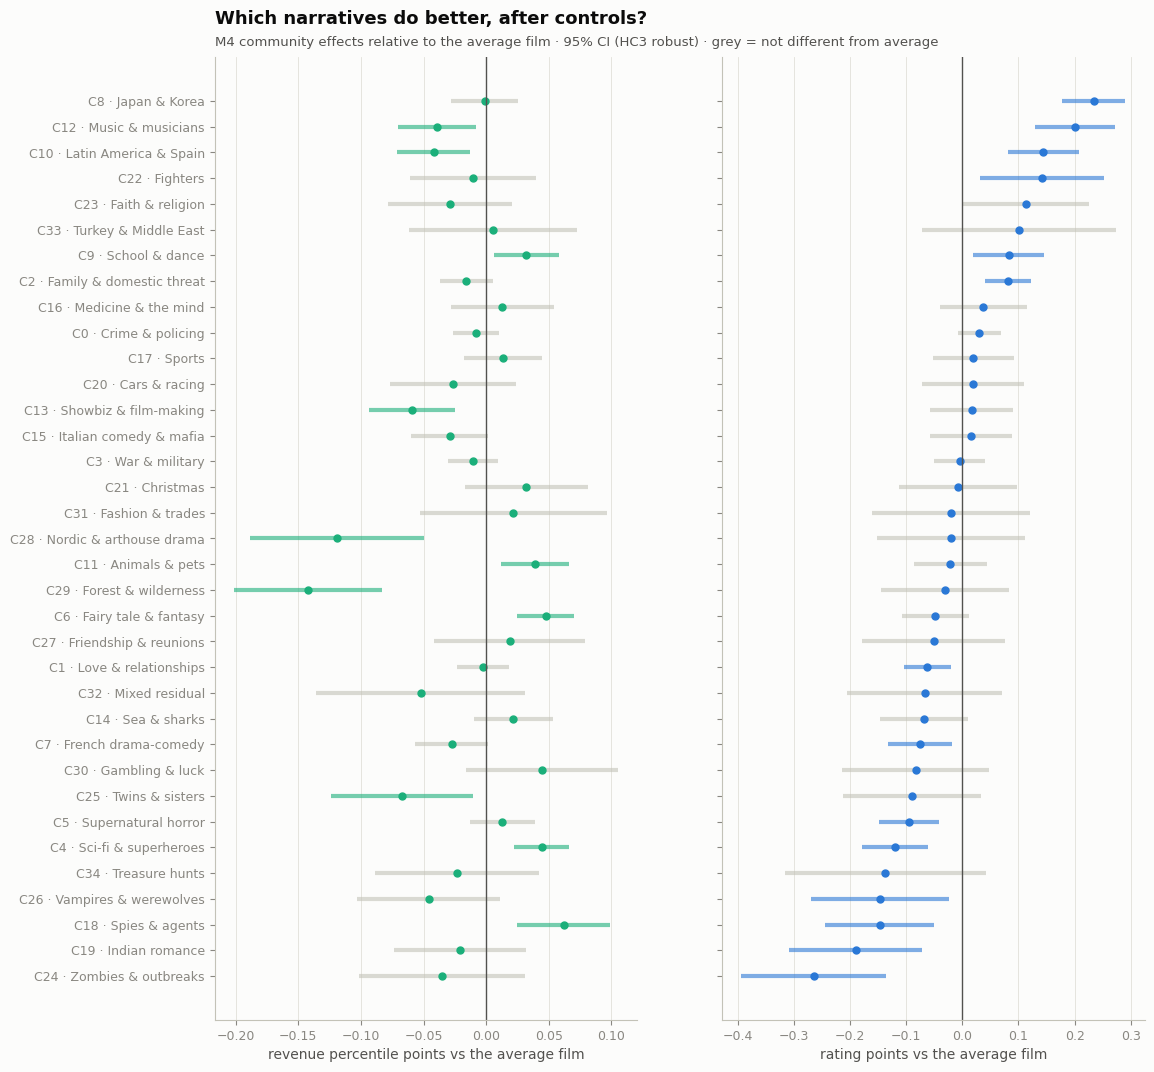

  ✓ figures/success/fig_04_community_effects.png + tables/success/fig_04_community_effects.csv


In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 12 — Community effects with 95% CIs (revenue percentile and rating)
# ═══════════════════════════════════════════════════════════════════════════
def community_effects(y):
    """Each community's effect minus the film-weighted average community effect (minor pool = reference 0),
    with standard errors from the clustered covariance (linear contrasts)."""
    # Standard errors clustered by community are NOT valid for the community dummies themselves (each dummy is
    # constant within its own cluster), so the community contrasts use heteroskedasticity-robust (HC3) errors.
    m4 = fits[(y, "M4_add_community")]
    res = smf.ols(m4.model.formula, data=m4.model.data.frame).fit(cov_type="HC3")
    terms = [t for t in res.params.index if t.startswith("C(community_group")]
    ids = [int(re.search(r"\[T\.C(\d+)\]", t).group(1)) for t in terms]
    data = res.model.data.frame
    w = data["community_group"].value_counts(normalize=True)
    wv = np.array([w.get(f"C{c}", 0.0) for c in ids])               # weight of each labelled community (minor adds 0)
    b, V_ = res.params[terms].values, res.cov_params().loc[terms, terms].values
    rows = []
    for i, c in enumerate(ids):
        L = -wv.copy(); L[i] += 1.0
        est, se = L @ b, np.sqrt(L @ V_ @ L)
        rows.append({"community_id": c, "coef": est, "ci_low": est - 1.96 * se, "ci_high": est + 1.96 * se,
                     "p_value": 2 * (1 - __import__("scipy").stats.norm.cdf(abs(est / se)))})
    return pd.DataFrame(rows)

eff = {y: community_effects(y) for y in ["revenue_percentile_year", "vote_average"]}
order = eff["vote_average"].sort_values("coef")["community_id"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 0.3 * len(order) + 2), sharey=True)
for ax, y, color, xl in zip(axes, ["revenue_percentile_year", "vote_average"], [SERIES[2], SERIES[0]],
                            ["revenue percentile points vs the average film", "rating points vs the average film"]):
    e = eff[y].set_index("community_id").reindex(order)
    yy = np.arange(len(order))
    sig = (e["ci_low"] > 0) | (e["ci_high"] < 0)
    ax.hlines(yy, e["ci_low"], e["ci_high"], color=np.where(sig, color, AXIS), linewidth=3, alpha=0.6)
    ax.plot(e["coef"], yy, "o", color=color, markersize=5)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_xlabel(xl)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(order)), [SHORT[c] for c in order])
axes[0].set_title("Which narratives do better, after controls?")
subtitle(axes[0], "M4 community effects relative to the average film · 95% CI (HC3 robust) · grey = not different from average")
comm_tab = (eff["revenue_percentile_year"][["community_id", "coef", "ci_low", "ci_high", "p_value"]]
            .add_prefix("revpct_").rename(columns={"revpct_community_id": "community_id"})
            .merge(eff["vote_average"][["community_id", "coef", "ci_low", "ci_high", "p_value"]].add_prefix("rating_")
                   .rename(columns={"rating_community_id": "community_id"}), on="community_id"))
comm_tab["label"] = comm_tab["community_id"].map(lab["suggested_label_manual"])
save(fig, comm_tab, "fig_04_community_effects")


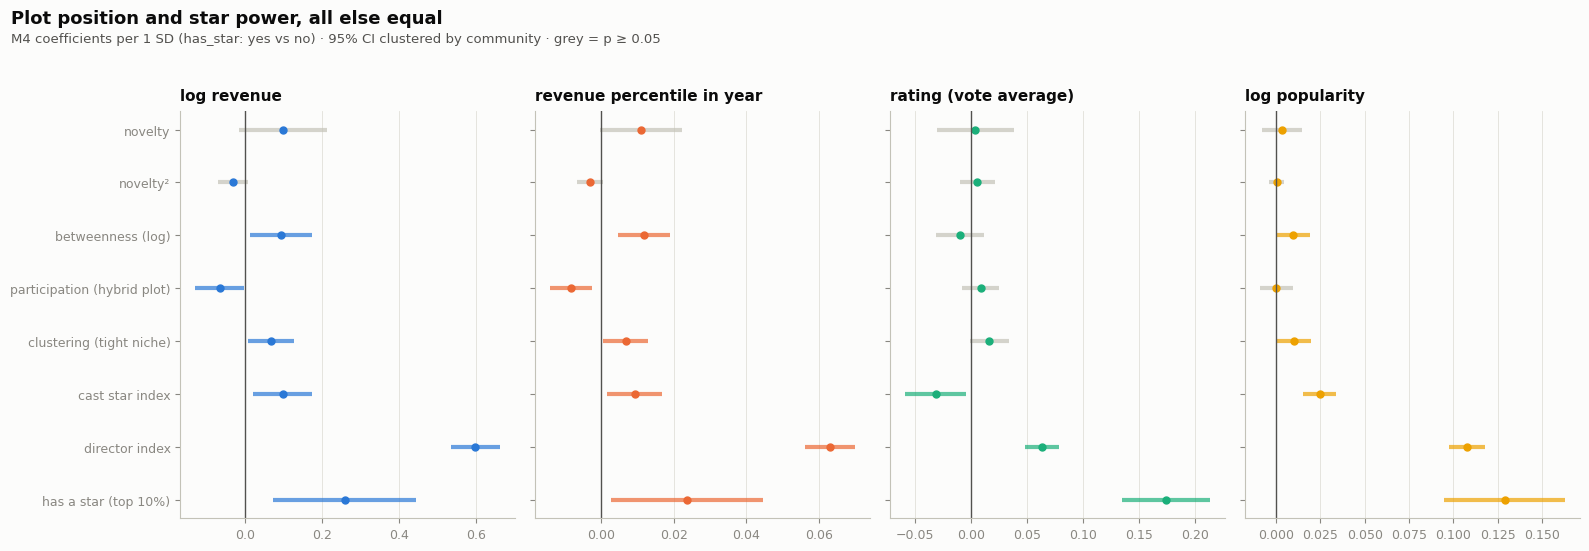

  ✓ figures/success/fig_05_coefficients.png + tables/success/fig_05_coefficients.csv


In [13]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 13 — Coefficient forest: plot-network and star terms across outcomes (M4)
# ═══════════════════════════════════════════════════════════════════════════
nice = {"z_novelty": "novelty", "z_novelty_sq": "novelty²", "z_log_betweenness": "betweenness (log)",
        "z_participation": "participation (hybrid plot)", "z_clustering": "clustering (tight niche)",
        "z_star_index": "cast star index", "z_director_index": "director index", "has_star": "has a star (top 10%)"}
k = key[key["model"] == "M4_add_community"].copy()
k["scaled"] = k.groupby("outcome")["coef"].transform(lambda x: x)            # per-outcome units
terms_order = [t for t in nice if t in k["term"].unique()]
fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(4.0 * len(OUTCOMES), 0.42 * len(terms_order) + 1.8), sharey=True)
for ax, y, color in zip(np.atleast_1d(axes), OUTCOMES, SERIES + [SERIES[0]]):
    t = k[k["outcome"] == y].set_index("term").reindex(terms_order)
    yy = np.arange(len(terms_order))[::-1]
    sig = t["p_value"] < 0.05
    ax.hlines(yy, t["ci_low"], t["ci_high"], color=np.where(sig, color, AXIS), linewidth=3, alpha=0.7)
    ax.plot(t["coef"], yy, "o", color=color, markersize=5)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_title(OUTCOMES[y], fontsize=11, pad=8)
    ax.grid(axis="y", visible=False)
np.atleast_1d(axes)[0].set_yticks(np.arange(len(terms_order))[::-1], [nice[t] for t in terms_order])
fig.suptitle("Plot position and star power, all else equal", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.06)
fig.text(0.01, 0.99, "M4 coefficients per 1 SD (has_star: yes vs no) · 95% CI clustered by community · grey = p ≥ 0.05",
         fontsize=9.5, color=INK_2, va="bottom")
fig.tight_layout()
save(fig, k[["outcome", "term", "coef", "ci_low", "ci_high", "p_value"]], "fig_05_coefficients")


## 9. Robustness

The M4 plot-network coefficients for revenue percentile and rating under alternative choices. A finding is robust if its sign and rough size survive most rows.

In [14]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 14 — Robustness checks
# ═══════════════════════════════════════════════════════════════════════════
M4 = SPECS["M4_add_community"]
fd = pd.read_csv(FRANCHISE_FILE) if FRANCHISE_FILE.exists() else pd.DataFrame(columns=["community_id"])
fd_ids = set(fd["community_id"])
checks = {
    "main (M4)": (lambda d: d, M4),
    "+ log budget (films with budget)": (lambda d: d.dropna(subset=["log_budget"]), M4 + " + log_budget"),
    "≥ 100 votes": (lambda d: d[d["vote_count"] >= CFG["robust_min_votes"]], M4),
    "labelled communities only, no franchise/name-driven": (lambda d: d[d["community_group"].ne("minor") & ~d["community_id"].isin(fd_ids)],
                                                           M4.replace(" + C(community_group, Treatment('minor'))", " + C(community_group)")),
    "network-reference revenue percentile": (lambda d: d.assign(revenue_percentile_year=d["pct_network"]), M4),
    "linear year instead of year fixed effects": (lambda d: d, M4.replace("C(release_year)", "release_year_centered")),
}
rows = []
for y in ["revenue_percentile_year", "vote_average"]:
    base_data = df.dropna(subset=[y] + list(dict.fromkeys(MODEL_VARS)))
    for name, (f, rhs) in checks.items():
        if y == "vote_average" and name == "network-reference revenue percentile":
            continue
        d = f(base_data).dropna(subset=[y])
        if len(d) < 300:
            continue
        res = fit(f"{y} ~ {rhs}", d)
        for t in NET.split(" + "):
            if t in res.params:
                rows.append({"outcome": y, "check": name, "term": t, "coef": res.params[t], "p_value": res.pvalues[t],
                             "n_obs": int(res.nobs)})

# logistic model for top-25% revenue: average marginal effects
d = df.dropna(subset=["high_revenue_year"] + list(dict.fromkeys(MODEL_VARS)))
try:
    lg = smf.logit(f"high_revenue_year ~ {M4}", data=d).fit(disp=0, cov_type="cluster",
                                                            cov_kwds={"groups": pd.factorize(d[CFG['cluster_se_by']])[0]})
    me = lg.get_margeff().summary_frame()
    for t in NET.split(" + "):
        if t in me.index:
            rows.append({"outcome": "high_revenue_year (logit AME)", "check": "logit, top 25% revenue", "term": t,
                         "coef": me.loc[t, "dy/dx"], "p_value": me.loc[t, "Pr(>|z|)"], "n_obs": int(lg.nobs)})
except Exception as ex:
    print("Logit skipped:", ex)
robust = pd.DataFrame(rows)
wide = robust.pivot_table(index=["outcome", "check"], columns="term", values="coef").round(4)
display(wide)
save_new(robust.round(5), "robustness_checks.csv")

# v1 specification, to document the collinearity artefact
v1_rhs = ("z_weighted_degree + z_pagerank + z_betweenness_centrality_sampled + z_clustering_coefficient + "
          "release_year_centered + C(primary_genre_model)")
v1rows = []
for y in ["log_revenue", "vote_average"]:
    d = df.dropna(subset=[y, "z_weighted_degree", "z_pagerank", "z_betweenness_centrality_sampled", "z_clustering_coefficient"])
    r1 = smf.ols(f"{y} ~ {v1_rhs}", d).fit(cov_type="HC3")
    r2_ = smf.ols(f"{y} ~ {v1_rhs.replace('z_pagerank + ', '')}", d).fit(cov_type="HC3")
    for lab_, r in [("v1 (weighted degree + PageRank)", r1), ("v1 without PageRank", r2_)]:
        for t in ["z_weighted_degree", "z_pagerank"]:
            if t in r.params:
                v1rows.append({"outcome": y, "specification": lab_, "term": t, "coef": r.params[t], "p_value": r.pvalues[t]})
v1tab = pd.DataFrame(v1rows)
print("\nv1 specification, with and without PageRank (compare the weighted-degree coefficient):")
display(v1tab.round(4))
save_new(v1tab.round(5), "v1_collinearity_demo.csv")


term                                                                               z_clustering  \
outcome                       check                                                               
high_revenue_year (logit AME) logit, top 25% revenue                                     0.0144   
revenue_percentile_year       + log budget (films with budget)                           0.0064   
                              labelled communities only, no franchise/name-driven        0.0056   
                              linear year instead of year fixed effects                  0.0068   
                              main (M4)                                                  0.0068   
                              network-reference revenue percentile                       0.0077   
                              ≥ 100 votes                                                0.0064   
vote_average                  + log budget (films with budget)                           0.0172   
                              labelled communities only, no franchise/name-driven        0.0107   
                              linear year instead of year fixed effects                  0.0148   
                              main (M4)                                                  0.0168   
                              ≥ 100 votes                                                0.0210   

term                                                                               z_log_betweenness  \
outcome                       check                                                                    
high_revenue_year (logit AME) logit, top 25% revenue                                          0.0227   
revenue_percentile_year       + log budget (films with budget)                                0.0056   
                              labelled communities only, no franchise/name-driven             0.0126   
                              linear year instead of year fixed effects                       0.0117   
                              main (M4)                                                       0.0120   
                              network-reference revenue percentile                            0.0131   
                              ≥ 100 votes                                                     0.0105   
vote_average                  + log budget (films with budget)                               -0.0005   
                              labelled communities only, no franchise/name-driven            -0.0051   
                              linear year instead of year fixed effects                      -0.0110   
                              main (M4)                                                      -0.0095   
                              ≥ 100 votes                                                    -0.0107   

term                                                                               z_novelty  \
outcome                       check                                                            
high_revenue_year (logit AME) logit, top 25% revenue                                  0.0076   
revenue_percentile_year       + log budget (films with budget)                        0.0047   
                              labelled communities only, no franchise/name-driven     0.0132   
                              linear year instead of year fixed effects               0.0108   
                              main (M4)                                               0.0110   
                              network-reference revenue percentile                    0.0117   
                              ≥ 100 votes                                             0.0135   
vote_average                  + log budget (films with budget)                       -0.0148   
                              labelled communities only, no franchise/name-driven     0.0180   
                              linear year instead of year fixed effects               0.0022   
    

  ✓ tables/success/robustness_checks.csv

v1 specification, with and without PageRank (compare the weighted-degree coefficient):


,outcome,specification,term,coef,p_value
0,log_revenue,v1 (weighted degree + PageRank),z_weighted_degree,-0.1593,0.0447
1,log_revenue,v1 (weighted degree + PageRank),z_pagerank,0.2836,0.0013
2,log_revenue,v1 without PageRank,z_weighted_degree,0.0359,0.4686
3,vote_average,v1 (weighted degree + PageRank),z_weighted_degree,-0.0883,0.0000
4,vote_average,v1 (weighted degree + PageRank),z_pagerank,0.0724,0.0002
5,vote_average,v1 without PageRank,z_weighted_degree,-0.0396,0.0001


  ✓ tables/success/v1_collinearity_demo.csv


In [15]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 15 — Community success summary (v1 file) and modelling table (v1 name)
# ═══════════════════════════════════════════════════════════════════════════
community_success_summary = (df.groupby(["community_id", "suggested_label_manual"])
    .agg(n_films=("title", "count"),
         revenue_available_pct=("revenue_clean", lambda x: round(x.notna().mean() * 100, 2)),
         median_revenue=("revenue_clean", "median"), median_log_revenue=("log_revenue", "median"),
         median_revenue_percentile_year=("revenue_percentile_year", "median"),
         median_vote_average=("vote_average", "median"), median_vote_count=("vote_count", "median"),
         median_popularity=("popularity", "median"), median_weighted_degree=("weighted_degree", "median"),
         median_betweenness=(BETW, "median"), median_cast_size=("cast_size", "median"),
         median_top_cast_exposure_max=("top_cast_exposure_max", "median"),
         median_novelty=("novelty", "median"), median_star_index=("star_index", "median"),
         share_english=("is_english", "mean"))
    .reset_index().sort_values("n_films", ascending=False))
save_v1(community_success_summary, "community_success_summary.csv")

df["cast_list"] = df["cast_clean"].fillna("")
df["top_cast_list"] = df["cast_clean"].fillna("")
df.to_csv(MODELING_TABLE_OUT, index=False, encoding="utf-8")
print(f"  ✓ processed/features/{MODELING_TABLE_OUT.name}  {df.shape}")


  ✓ tables/community_success_summary.csv
  ✓ processed/features/modeling_table_success_star_power.csv  (19084, 89)


In [16]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 16 — Notes for the Results chapter (written from the numbers)
# ═══════════════════════════════════════════════════════════════════════════
def fmt(y, t, m="M4_add_community"):
    r = tables[y].set_index(["model", "term"]).loc[(m, t)] if (m, t) in tables[y].set_index(["model", "term"]).index else None
    return "n/a" if r is None else f"{r['coef']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}], p={r['p_value']:.3g}"

lines = ["Success analysis notes", "",
         f"Network films: {len(df):,}; revenue known for {int(has_rev.sum()):,} ({has_rev.mean():.0%}). Revenue models "
         "describe the reported-revenue market; films with revenue are more visible and more often English-language.",
         f"Revenue percentile reference: {CFG['revenue_reference']}. Star power uses only films from earlier years "
         "(cast and director prior reach), so no future information enters the predictors."]
for y in OUTCOMES:
    g = gain.loc[y]
    w = r2[(r2["outcome"] == y) & r2["model"].str.startswith("joint")].iloc[0]
    lines.append(f"{OUTCOMES[y]}: R² {fitrows.loc[y, 'M1_controls']:.3f} with controls; plot network adds "
                 f"{g['+ plot network']:.3f}, star power {g['+ star power']:.3f}, community {g['+ community']:.3f}. "
                 f"Plot-network block jointly {'significant' if w['wald_p'] < 0.05 else 'not significant'} in M4 (p={w['wald_p']:.2g}).")
for r in turning.itertuples():
    lines.append(f"Novelty → {OUTCOMES[r.outcome]}: {r.shape}"
                 + (f", peak at {r.turning_point_sd:+.2f} SD" if r.shape == "inverted U" and pd.notna(r.turning_point_sd) else "") + ".")
sig_comm = comm_tab[(comm_tab["rating_p_value"] < 0.05)].sort_values("rating_coef")
if len(sig_comm):
    lo, hi = sig_comm.iloc[0], sig_comm.iloc[-1]
    lines.append(f"Community differences in rating after controls: highest {hi['label']} ({hi['rating_coef']:+.2f}), "
                 f"lowest {lo['label']} ({lo['rating_coef']:+.2f}) relative to the average film; "
                 f"{len(sig_comm)} of {len(comm_tab)} labelled communities differ significantly from average.")
vt = v1tab[(v1tab["outcome"] == "log_revenue") & (v1tab["term"] == "z_weighted_degree")].set_index("specification")["coef"]
rho_wp = df[["weighted_degree", "pagerank"]].corr(method="spearman").iloc[0, 1]
if len(vt) == 2:
    lines.append(f"v1 specification check: weighted degree and PageRank correlate at ρ = {rho_wp:.2f}. On log revenue the "
                 f"weighted-degree coefficient is {vt.iloc[0]:+.3f} with PageRank in the model and {vt.iloc[1]:+.3f} without it"
                 + (" — the v1 estimates were driven by collinearity." if abs(vt.iloc[0] - vt.iloc[1]) > 0.5 * max(abs(vt.iloc[1]), 0.05)
                    else " — little change, so collinearity did not drive this coefficient.")
                 + " v2's main models do not use these two measures.")
lines.append("All results are associations, not causal effects.")
notes = "\n".join(lines)
(TABLES_DIR / "success_star_power_notes.txt").write_text(notes, encoding="utf-8")
print(notes)
print("\n  ✓ tables/success_star_power_notes.txt")


Success analysis notes

Network films: 19,084; revenue known for 7,547 (40%). Revenue models describe the reported-revenue market; films with revenue are more visible and more often English-language.
Revenue percentile reference: market. Star power uses only films from earlier years (cast and director prior reach), so no future information enters the predictors.
log revenue: R² 0.238 with controls; plot network adds 0.004, star power 0.051, community 0.012. Plot-network block jointly significant in M4 (p=0.0016).
revenue percentile in year: R² 0.233 with controls; plot network adds 0.005, star power 0.059, community 0.013. Plot-network block jointly significant in M4 (p=0.00023).
rating (vote average): R² 0.259 with controls; plot network adds 0.000, star power 0.006, community 0.010. Plot-network block jointly not significant in M4 (p=0.1).
log popularity: R² 0.158 with controls; plot network adds 0.001, star power 0.045, community 0.007. Plot-network block jointly significant in M4 (

## What comes next

* The presentation bricks (08_01 … 08_08) read the files written here and in Notebook 04 under their v1 names.
* For the Results chapter: Figure 2 (what plot position adds), Figure 3 (novelty sweet spot), Figure 4 (community effects) and Figure 5 (coefficients) carry the main findings; `success/robustness_checks.csv` backs them up.